# Residual-Based Drift Detector Evaluation & Benchmark Comparison om Milti Series

In [1]:
# Import required libraries
import sys
import os
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Add parent directory to path
sys.path.append(os.path.abspath(os.path.join('..')))

# Import project custom modules
from src.detector.data_loader import DataLoader
from src.detector.drift_generator import DriftGenerator
from src.detector.baseline_detectors import BaselineDetectorWrapper
from src.detector.residual_detector import ResidualConformalDriftDetector
from src.detector.generate_benchmarks import generate_multi_series_benchmarks
from src.detector.run_baseline_evaluation import run_all_baseline_detectors
from src.detector.run_residual_detector_evaluation import evaluate_residual_detector

# Styling setup
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

## Input data

In [2]:
data_dir = "../data"
processed_dir = Path(data_dir) / "processed"
manifest_path = processed_dir / "multi_series_benchmark_manifest.json"
baseline_results_path = processed_dir / "multi_series_baseline_evaluation_results.csv"

tcpd_list_of_datasets = ["jfk_passengers", "iceland_tourism", "us_population"]

tcpd_frequency_mapping = {
    "jfk_passengers": "MS",
    "lga_passengers": "MS",
    "construction": "MS",
    "iceland_tourism": "MS",
    "seatbelts": "MS",
    "us_population": "MS",
    "occupancy": "1min",
    "measles": "W"
}

tcpd_annotator_key_mapping = {
    "jfk_passengers": "10",
    "lga_passengers": "6",
    "construction": "8",
    "iceland_tourism": "12",
    "seatbelts": "8",
    "us_population": "9",
    "occupancy": "6",
    "measles": "12"
}

## 1. Data Reading

In [3]:
# Initialize data loader
loader = DataLoader(data_dir="../data")

# Load multi-series dictionaries
datasets = {
    "Alibaba": loader.load_alibaba_batch(n_series=2, seed=42),
    "UCI_Electricity": loader.load_uci_batch(n_series=5, resample_freq="1h", seed=42),
    "TCPD": loader.load_tcpd_batch(series_names=tcpd_list_of_datasets, frequency=tcpd_frequency_mapping, annotator_key=tcpd_annotator_key_mapping),
    # "SeisBench Iquique": loader.load_seisbench_iquique_batch(n_series=10, seed=42),
}

# Quick inspection loop to verify structure
for ds_name, series_dict in datasets.items():
    print(f"Dataset: {ds_name} | Loaded {len(series_dict)} time series.")
    for series_id, payload in list(series_dict.items())[:10]: # Preview first 10
        df, period = payload[0], payload[1]
        print(f"  -> Series ID: {series_id} | Shape: {df.shape} | Seasonal Period: {period}")

Dataset: Alibaba | Loaded 2 time series.
  -> Series ID: alibaba_mem_util_percent | Shape: (2243, 2) | Seasonal Period: 288
  -> Series ID: alibaba_net_in | Shape: (2243, 2) | Seasonal Period: 288
Dataset: UCI_Electricity | Loaded 5 time series.
  -> Series ID: MT_242 | Shape: (35064, 2) | Seasonal Period: 24
  -> Series ID: MT_241 | Shape: (35064, 2) | Seasonal Period: 24
  -> Series ID: MT_291 | Shape: (35064, 2) | Seasonal Period: 24
  -> Series ID: MT_209 | Shape: (35064, 2) | Seasonal Period: 24
  -> Series ID: MT_265 | Shape: (35064, 2) | Seasonal Period: 24
Dataset: TCPD | Loaded 3 time series.
  -> Series ID: jfk_passengers | Shape: (468, 2) | Seasonal Period: 12
  -> Series ID: iceland_tourism | Shape: (199, 2) | Seasonal Period: 12
  -> Series ID: us_population | Shape: (816, 2) | Seasonal Period: 12


## 2. Drift Benchmark Generation

In [4]:
generate_multi_series_benchmarks(datasets, data_dir="../data")

=== Starting 3-Level Multi-Series Benchmark Generation ===

Processing dataset batch: 'Alibaba' (2 time series)
 -> Processing series ID: alibaba_mem_util_percent
    [Level 1] Saved clean baseline -> level1_clean_Alibaba_alibaba_mem_util_percent.csv
    [Level 2] Completed drift injections for Alibaba-alibaba_mem_util_percent
 -> Processing series ID: alibaba_net_in
    [Level 1] Saved clean baseline -> level1_clean_Alibaba_alibaba_net_in.csv
    [Level 2] Completed drift injections for Alibaba-alibaba_net_in

Processing dataset batch: 'UCI_Electricity' (5 time series)
 -> Processing series ID: MT_242
    [Level 1] Saved clean baseline -> level1_clean_UCI_Electricity_MT_242.csv
    [Level 2] Completed drift injections for UCI_Electricity-MT_242
 -> Processing series ID: MT_241
    [Level 1] Saved clean baseline -> level1_clean_UCI_Electricity_MT_241.csv
    [Level 2] Completed drift injections for UCI_Electricity-MT_241
 -> Processing series ID: MT_291
    [Level 1] Saved clean baseli

## 3. Baseline Detector Evaluation

In [5]:
baseline_evaluation_df = run_all_baseline_detectors(data_dir="../data", manifest_file="multi_series_benchmark_manifest.json", output_file="multi_series_baseline_evaluation_results.csv")

=== Starting Baseline Detector Evaluation (3-Level Benchmark) ===
[Level 1 FAR] ks on Alibaba: 23.63 alarms/1000 pts
[Level 1 FAR] psi on Alibaba: 36.11 alarms/1000 pts
[Level 1 FAR] wasserstein on Alibaba: 31.65 alarms/1000 pts
[Level 1 FAR] adwin on Alibaba: 5.35 alarms/1000 pts
[Level 1 FAR] page_hinkley on Alibaba: 12.48 alarms/1000 pts
[Level 1 FAR] kswin on Alibaba: 8.47 alarms/1000 pts
[Level 1 FAR] ks on Alibaba: 35.67 alarms/1000 pts
[Level 1 FAR] psi on Alibaba: 36.56 alarms/1000 pts
[Level 1 FAR] wasserstein on Alibaba: 0.45 alarms/1000 pts
[Level 1 FAR] adwin on Alibaba: 1.78 alarms/1000 pts
[Level 1 FAR] page_hinkley on Alibaba: 0.89 alarms/1000 pts
[Level 1 FAR] kswin on Alibaba: 9.36 alarms/1000 pts
[Level 1 FAR] ks on UCI_Electricity: 3.14 alarms/1000 pts
[Level 1 FAR] psi on UCI_Electricity: 36.48 alarms/1000 pts
[Level 1 FAR] wasserstein on UCI_Electricity: 39.78 alarms/1000 pts
[Level 1 FAR] adwin on UCI_Electricity: 0.23 alarms/1000 pts
[Level 1 FAR] page_hinkley on

## 4. ResidualConformalDriftDetector on Benchmarks

In [6]:
with open(manifest_path, "r") as f:
    benchmark_manifest = json.load(f)

print(f"Total benchmark scenarios in manifest: {len(benchmark_manifest)}")

Total benchmark scenarios in manifest: 97


In [7]:
# Execute evaluation
df_residual = evaluate_residual_detector(benchmark_manifest, processed_dir)
display(df_residual.head())

,dataset,level,drift_type,magnitude,method,false_alarms,far_per_1000,precision,recall,f1_score,detection_delay,detected
0,level1_clean_Alibaba_alibaba_mem_util_percent.csv,1,none,0.0,residual_conformal,33,14.712439,0.000000,0.0,0.000000,NaN,False
1,level2_Alibaba_alibaba_mem_util_percent_abrupt...,2,abrupt,0.5,residual_conformal,27,NaN,0.035714,1.0,0.068966,32.0,True
2,level2_Alibaba_alibaba_mem_util_percent_abrupt...,2,abrupt,1.0,residual_conformal,26,NaN,0.037037,1.0,0.071429,32.0,True
3,level2_Alibaba_alibaba_mem_util_percent_abrupt...,2,abrupt,2.0,residual_conformal,27,NaN,0.035714,1.0,0.068966,32.0,True
4,level2_Alibaba_alibaba_mem_util_percent_abrupt...,2,abrupt,3.0,residual_conformal,24,NaN,0.040000,1.0,0.076923,37.0,True


## 5. Combine Multi series Results & Compare with Classic Methods

In [8]:
df_baseline = pd.read_csv(baseline_results_path)
print(f"Loaded baseline results shape: {df_baseline.shape}")
display(df_baseline.head())

Loaded baseline results shape: (582, 12)


,dataset,level,drift_type,magnitude,method,false_alarms,far_per_1000,precision,recall,f1_score,detection_delay,detected
0,Alibaba,1,none,0.0,ks,53.0,23.63,0.0,0.0,0.0,NaN,NaN
1,Alibaba,1,none,0.0,psi,81.0,36.11,0.0,0.0,0.0,NaN,NaN
2,Alibaba,1,none,0.0,wasserstein,71.0,31.65,0.0,0.0,0.0,NaN,NaN
3,Alibaba,1,none,0.0,adwin,12.0,5.35,0.0,0.0,0.0,NaN,NaN
4,Alibaba,1,none,0.0,page_hinkley,28.0,12.48,0.0,0.0,0.0,NaN,NaN


In [9]:
# Combine baseline and residual conformal detector results
df_comparison = pd.concat([df_baseline, df_residual], ignore_index=True)

# Save combined comparison results
df_comparison.to_csv(processed_dir / "multi_series_detector_comparison_results.csv", index=False)

df_comparison_level_1 = df_comparison[df_comparison['level'] == 1][["dataset", "level", "drift_type", "method", "false_alarms", "far_per_1000"]]
df_comparison_level_2 = df_comparison[df_comparison['level'] == 2][["dataset", "level", "drift_type", "magnitude", "method", "precision", "recall", "f1_score", "detection_delay", "detected"]]
df_comparison_level_3 = df_comparison[(df_comparison['level'] == 3) & (~df_comparison['dataset'].isin(["seismic_iquique_trace"]))][["dataset", "level", "drift_type", "method", "precision", "recall", "f1_score", "detection_delay", "detected"]]

## 6. Comparative Visualization

### 6.1 Level 1 Analysis: False Alarm Rate (FAR)

In [10]:
print("=== Level 1: Drift-Free False Alarm Summary ===")
summary_level_1 = df_comparison_level_1.groupby("method")[["false_alarms", "far_per_1000"]].mean().reset_index()
display(summary_level_1)

=== Level 1: Drift-Free False Alarm Summary ===


,method,false_alarms,far_per_1000
0,adwin,6.3,0.847000
1,ks,57.1,7.179000
2,kswin,50.6,3.613000
3,page_hinkley,591.8,27.521000
4,psi,656.8,30.367000
5,residual_conformal,106.1,6.513666
6,wasserstein,708.3,28.514000


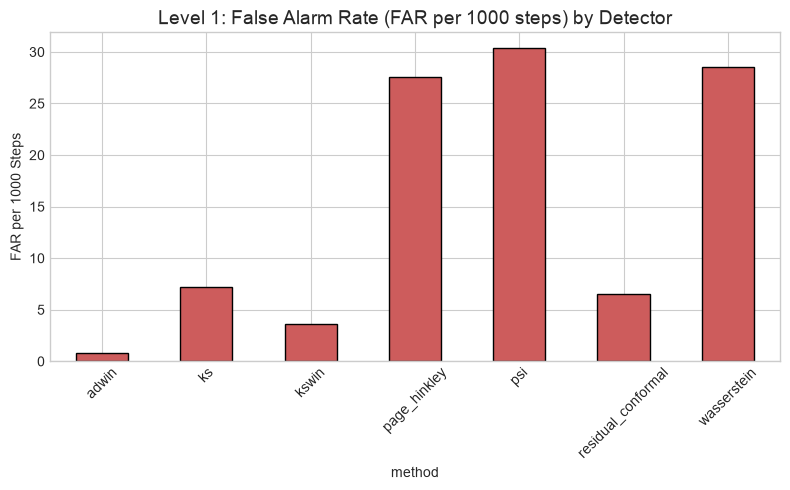

In [11]:
# Level 1 Plot: False Alarms by Detector
fig, ax = plt.subplots(figsize=(8, 5))
summary_level_1.set_index("method")["far_per_1000"].plot(kind="bar", ax=ax, color="indianred", edgecolor="black")
ax.set_title("Level 1: False Alarm Rate (FAR per 1000 steps) by Detector", fontsize=14)
ax.set_ylabel("FAR per 1000 Steps")
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

### 6.2 Level 2 & 3 Analysis: Detection Performance

#### Level 2 Analysis

In [12]:
print("\n=== Level 2: Detection Performance Summary ===")
summary_levels_2 = df_comparison_level_2.groupby("method")[["f1_score", "precision", "recall", "detection_delay"]].mean().reset_index()
display(summary_levels_2)


=== Level 2: Detection Performance Summary ===


,method,f1_score,precision,recall,detection_delay
0,adwin,0.054286,0.028333,0.642857,230.904762
1,ks,0.026071,0.013690,0.988095,14.595238
2,kswin,0.029762,0.015476,0.595238,46.333333
3,page_hinkley,0.013929,0.007738,0.821429,25.297619
4,psi,0.014286,0.008571,1.000000,14.000000
5,residual_conformal,0.024338,0.012478,0.976190,15.439024
6,wasserstein,0.013571,0.007143,0.928571,19.952381


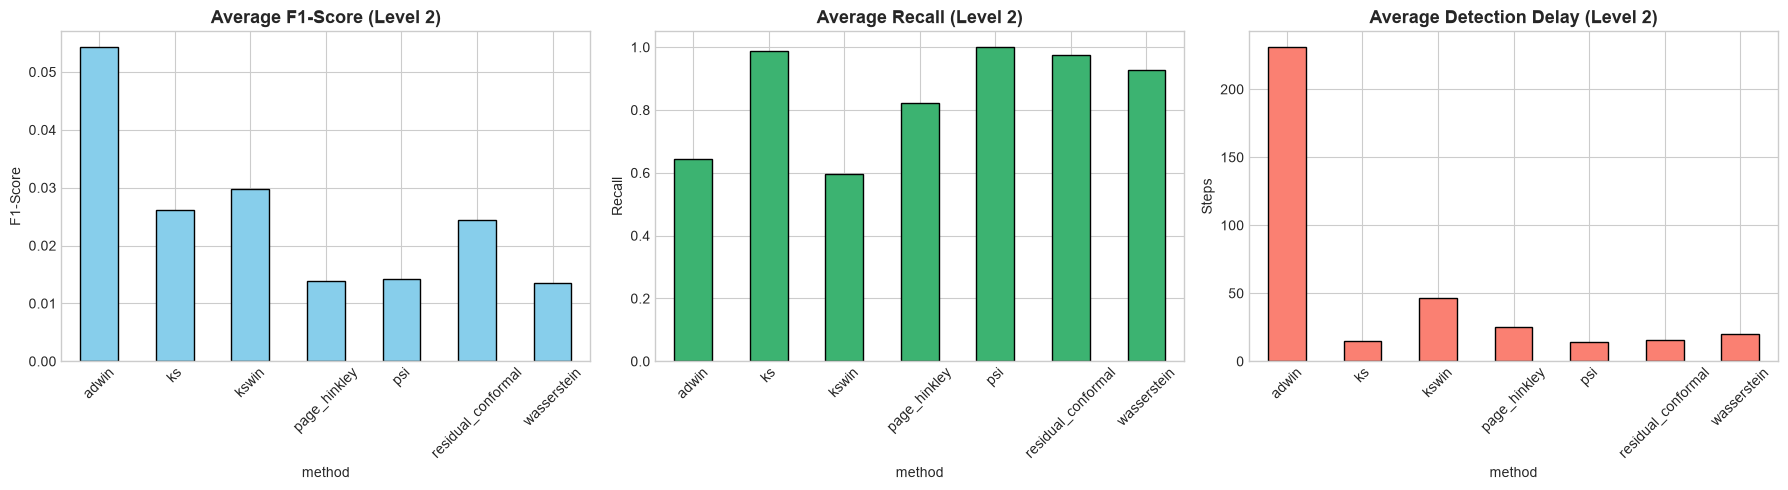

In [13]:
# Level 2 Plot: F1-Score, Recall, and Detection Delay
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. F1-Score Comparison
summary_levels_2.set_index("method")["f1_score"].plot(kind="bar", ax=axes[0], color="skyblue", edgecolor="black")
axes[0].set_title("Average F1-Score (Level 2)", fontsize=13, fontweight="bold")
axes[0].set_ylabel("F1-Score")
axes[0].tick_params(axis='x', rotation=45)

# 2. Recall Comparison
summary_levels_2.set_index("method")["recall"].plot(kind="bar", ax=axes[1], color="mediumseagreen", edgecolor="black")
axes[1].set_title("Average Recall (Level 2)", fontsize=13, fontweight="bold")
axes[1].set_ylabel("Recall")
axes[1].tick_params(axis='x', rotation=45)

# 3. Detection Delay Comparison
summary_levels_2.set_index("method")["detection_delay"].plot(kind="bar", ax=axes[2], color="salmon", edgecolor="black")
axes[2].set_title("Average Detection Delay (Level 2)", fontsize=13, fontweight="bold")
axes[2].set_ylabel("Steps")
axes[2].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

#### Level 3 Analysis

In [14]:
print("\n=== Level 3: Detection Performance Summary ===")
summary_levels_3 = df_comparison_level_3.groupby("method")[["f1_score", "precision", "recall", "detection_delay"]].mean().reset_index()
display(summary_levels_3)


=== Level 3: Detection Performance Summary ===


,method,f1_score,precision,recall,detection_delay
0,adwin,0.250000,0.180000,0.666667,20.500000
1,ks,0.100000,0.053333,0.666667,8.500000
2,kswin,0.073333,0.040000,0.333333,37.000000
3,page_hinkley,0.160000,0.093333,1.000000,10.666667
4,psi,0.083333,0.043333,0.666667,8.500000
5,residual_conformal,0.688889,0.583333,1.000000,10.666667
6,wasserstein,0.083333,0.043333,0.666667,8.500000


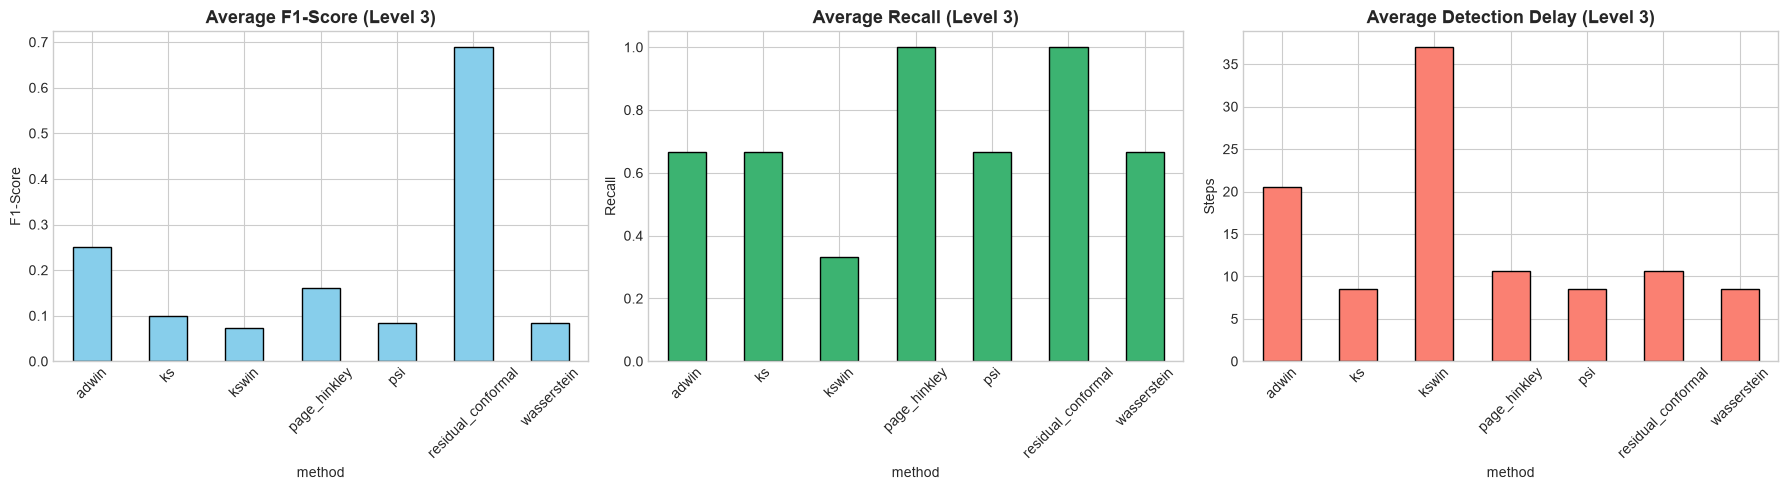

In [15]:
# Level 3 Plot: F1-Score, Recall, and Detection Delay
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. F1-Score Comparison
summary_levels_3.set_index("method")["f1_score"].plot(kind="bar", ax=axes[0], color="skyblue", edgecolor="black")
axes[0].set_title("Average F1-Score (Level 3)", fontsize=13, fontweight="bold")
axes[0].set_ylabel("F1-Score")
axes[0].tick_params(axis='x', rotation=45)

# 2. Recall Comparison
summary_levels_3.set_index("method")["recall"].plot(kind="bar", ax=axes[1], color="mediumseagreen", edgecolor="black")
axes[1].set_title("Average Recall (Level 3)", fontsize=13, fontweight="bold")
axes[1].set_ylabel("Recall")
axes[1].tick_params(axis='x', rotation=45)

# 3. Detection Delay Comparison
summary_levels_3.set_index("method")["detection_delay"].plot(kind="bar", ax=axes[2], color="salmon", edgecolor="black")
axes[2].set_title("Average Detection Delay (Level 3)", fontsize=13, fontweight="bold")
axes[2].set_ylabel("Steps")
axes[2].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

#### Level 2 & 3 Combined Analysis

In [16]:
# Combine Level 2 and 3 for overall detection capability evaluation
df_comparison_levels_2_3 = pd.concat([df_comparison_level_2, df_comparison_level_3])

print("\n=== Level 2 & 3: Detection Performance Summary ===")
summary_levels_2_3 = df_comparison_levels_2_3.groupby("method")[["f1_score", "precision", "recall", "detection_delay"]].mean().reset_index()
display(summary_levels_2_3)


=== Level 2 & 3: Detection Performance Summary ===


,method,f1_score,precision,recall,detection_delay
0,adwin,0.061034,0.033563,0.643678,226.011628
1,ks,0.028621,0.015057,0.977011,14.453488
2,kswin,0.031264,0.016322,0.586207,46.223529
3,page_hinkley,0.018966,0.010690,0.827586,24.793103
4,psi,0.016667,0.009770,0.988506,13.872093
5,residual_conformal,0.047254,0.032163,0.977011,15.270588
6,wasserstein,0.015977,0.008391,0.919540,19.686047


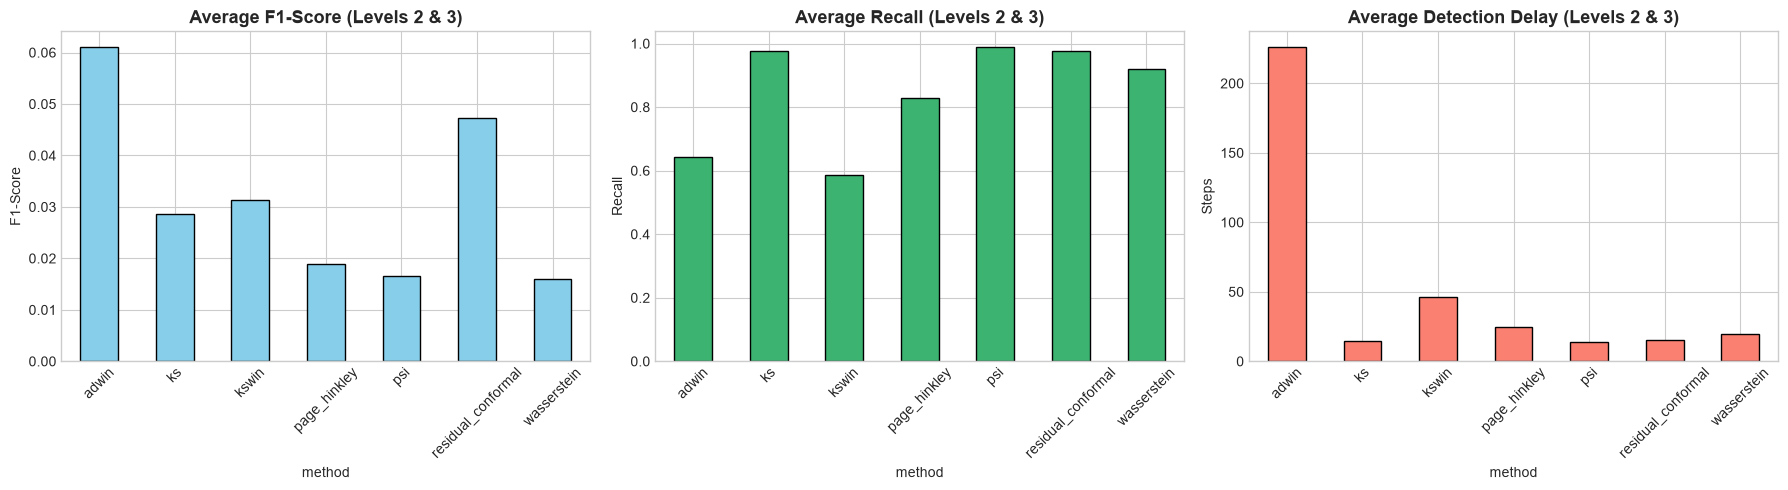

In [17]:
# Level 2 & 3 Plots: F1-Score, Recall, and Detection Delay
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. F1-Score Comparison
summary_levels_2_3.set_index("method")["f1_score"].plot(kind="bar", ax=axes[0], color="skyblue", edgecolor="black")
axes[0].set_title("Average F1-Score (Levels 2 & 3)", fontsize=13, fontweight="bold")
axes[0].set_ylabel("F1-Score")
axes[0].tick_params(axis='x', rotation=45)

# 2. Recall Comparison
summary_levels_2_3.set_index("method")["recall"].plot(kind="bar", ax=axes[1], color="mediumseagreen", edgecolor="black")
axes[1].set_title("Average Recall (Levels 2 & 3)", fontsize=13, fontweight="bold")
axes[1].set_ylabel("Recall")
axes[1].tick_params(axis='x', rotation=45)

# 3. Detection Delay Comparison
summary_levels_2_3.set_index("method")["detection_delay"].plot(kind="bar", ax=axes[2], color="salmon", edgecolor="black")
axes[2].set_title("Average Detection Delay (Levels 2 & 3)", fontsize=13, fontweight="bold")
axes[2].set_ylabel("Steps")
axes[2].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()